# 7 · Recommend: competitors, better-aligned niches, and what users complain about

**Syllabus:** Module 5 (content-based filtering, hybrid recommenders, evaluating
recommenders).

The engine recommends three things for an idea:

1. **Similar apps** (likely competitors): content-based filtering. The "content" of an
   app is its name as TF-IDF character n-grams; similarity is cosine.
2. **Better-aligned niches**: a hybrid. The content part finds which genres the idea's
   wider neighbourhood (100 apps) falls into; the market part weights each genre by its
   success rate. Ranked by closeness × success rate.
3. **Complaint topics** of the category: words typical of that category's negative
   reviews, compared with negative reviews elsewhere.

**Why not collaborative filtering?** Collaborative filtering recommends from other
users' behaviour ("people who installed this also installed..."). The data has no
user identities, no install histories and no per-user ratings, only anonymous review
texts. Content is what the data has, so content-based filtering is what fits; the
hybrid adds market data instead of user data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import common as C
import engine as E

C.style()
rng = np.random.default_rng(C.SEED)
apps = C.load_apps()
apps["split"] = C.split(apps)
pool, test = apps[apps["split"] != "test"].drop(columns="split").reset_index(drop=True), apps[apps["split"] == "test"].reset_index(drop=True)
eng = E.fit(pool)

## 7.1 Are the similar apps really similar?

For every held-out test app, its name is typed in as an idea and the engine recommends
the k most similar apps from the rest of the store. A recommendation counts as
relevant if it is in the **same genre** as the test app: the engine never sees the
genre, so this is a fair check. **Precision@k** is the share of the k recommendations
that are relevant. Two baselines, as in any recommender evaluation:

* **Random:** k apps drawn at random.
* **Popularity:** the k most-installed apps in the store, the same for everyone.

    content-based (engine)  popularity  random
1                    0.396       0.025   0.037
5                    0.336       0.024   0.035
10                   0.303       0.030   0.034
25                   0.252       0.033   0.034


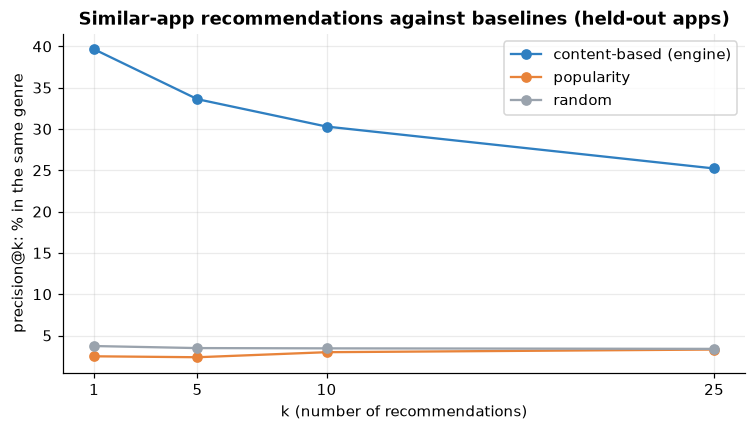

In [2]:
X = eng.vec.transform(test["app"].map(E.normalise))
ks = [1, 5, 10, 25]
sim, idx = eng.neighbours(X, k=max(ks))
rec_genre = pool["genre"].to_numpy()[idx]
truth = test["genre"].to_numpy()[:, None]
popular = pool.sort_values(["installs", "reviews"], ascending=False).index[:max(ks)]
rand = rng.integers(0, len(pool), size=(len(test), max(ks)))
prec = {}
for k in ks:
    prec[k] = {"content-based (engine)": float((rec_genre[:, :k] == truth).mean()),
               "popularity": float((pool["genre"].to_numpy()[popular[:k]][None, :] == truth).mean()),
               "random": float((pool["genre"].to_numpy()[rand[:, :k]] == truth).mean())}
prec = pd.DataFrame(prec).T
print(prec.round(3))
C.record("recommend.precision_at_k", prec.round(4).to_dict(orient="index"))
same_cat = float((pool["category"].to_numpy()[idx[:, :5]] == test["category"].to_numpy()[:, None]).mean())
C.record("recommend.precision5_same_category", same_cat)

fig, ax = plt.subplots(figsize=(8, 4))
for col, c in zip(prec.columns, [C.PALETTE["main"], C.PALETTE["accent"], C.PALETTE["muted"]]):
    ax.plot(prec.index, prec[col] * 100, marker="o", label=col, color=c)
ax.set_xlabel("k (number of recommendations)"); ax.set_ylabel("precision@k: % in the same genre")
ax.set_xticks(ks); ax.legend(); ax.set_title("Similar-app recommendations against baselines (held-out apps)")
C.save(fig, "recommend_precision")

Precision falls as k grows, as it should: the closest names are the most alike. Even
at 25 recommendations, the content-based list is far more relevant than popularity or
chance.

## 7.2 Complaint topics by category

Negative reviews of each category are compared with negative reviews of all other
categories (smoothed log-odds), so that words which only say "bad" cancel out and
what is bad remains. A word must appear in complaints about at least three different
apps. These describe the established apps that have reviews (chapter 1), which is the
competition a new idea will face.

In [3]:
complaints = E.complaint_words(C.load_reviews(), apps)
for cat_name, words in complaints.items():
    print(f"{cat_name:22s} {', '.join(words)}")
C.record("recommend.complaints", complaints)

ART_AND_DESIGN         color, save, working, thing, bad, hate, really, like
BEAUTY                 fake, install, time
BOOKS_AND_REFERENCE    books, library, reader, book, reading, read, pages, page
BUSINESS               laptop, business, calls, active, desktop, chat, file, extremely
COMMUNICATION          contacts, messaging, group, gmail, stock, cache, messages, desktop
DATING                 dating, men, profiles, meet, profile, miles, girls, proof
EDUCATION              learning, question, learn, text, wrong, way, know, bad
ENTERTAINMENT          cable, episodes, cast, movies, episode, channel, provider, netflix
FAMILY                 son, loves, daughter, child, record, cheating, bars, fixes
FINANCE                banks, fingerprint, deposit, loan, branch, ssn, banking, payments
FOOD_AND_DRINK         delivery, recipe, orders, cold, restaurant, deliver, delivered, recipes
GAME                   battle, boosters, crush, hints, attack, powerups, recharge, bonuses
HEALTH_AND_FITNESS

## 7.3 Case studies: five ideas, end to end

The whole engine, now fitted on every 2018 app, on five ideas of the kind a student
founder might bring. These are the examples used in the report and the demo.


pomodoro study timer for students
  EDUCATION | score 48.2 (Tough market) | P(1M+) 30%
  competitors: Students.ch, DS-Students, BU Study
  niches: Education, Productivity, Social | complaints: learning, question, learn, text, wrong

AI photo editor that removes backgrounds
  PHOTOGRAPHY | score 87.2 (Strong opportunity) | P(1M+) 69%
  competitors: CG Backgrounds, Best CG Backgrounds, Blur Image Background Editor (Blur Photo Editor)
  niches: Photography, Personalization, Entertainment | complaints: pics, photos, camera, image, photo

budget expense tracker for college students
  FINANCE | score 29.9 (Tough market) | P(1M+) 16%
  competitors: Money Lover: Expense Tracker, Budget Planner, Money Manager Expense & Budget, Students.ch
  niches: Health & Fitness, Finance, Education | complaints: banks, fingerprint, deposit, loan, branch

recipe app that plans meals from what is in your fridge
  FOOD_AND_DRINK | score 65.1 (Promising) | P(1M+) 44%
  competitors: Cook'n Recipe App, Simple Rec

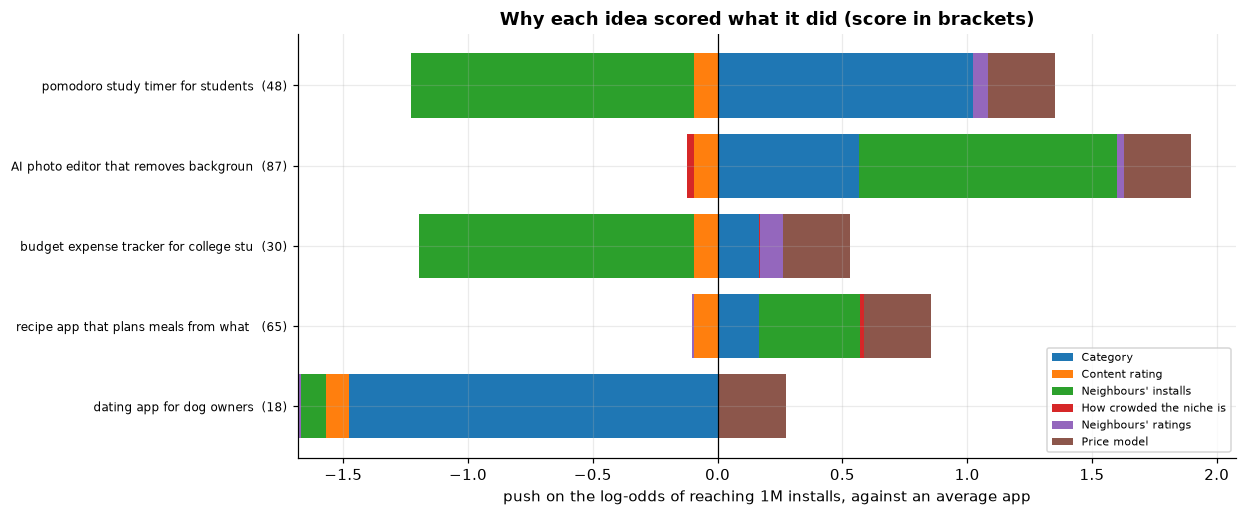

In [4]:
eng = E.fit(apps.drop(columns="split"), C.load_reviews())
IDEAS = ["pomodoro study timer for students", "AI photo editor that removes backgrounds",
         "budget expense tracker for college students", "recipe app that plans meals from what is in your fridge",
         "dating app for dog owners"]
cases = {}
for idea in IDEAS:
    r = eng.evaluate(idea)
    cases[idea] = {"category": r["category"], "category_guess": r["category_guess"], "score": r["score"], "verdict": r["verdict"],
                   "p_success": r["p_success"], "market": r["market"], "drivers": r["drivers"]["contributions"],
                   "competitors": r["competitors"].head(5)[["app", "installs", "rating", "similarity"]].round(3).to_dict(orient="records"),
                   "niches": r["suggestions"]["niches"].head(3)[["genre", "success_rate", "closeness"]].round(3).to_dict(orient="records"),
                   "complaints": r["suggestions"]["complaints"][:5], "winning_words": r["suggestions"]["winning_words"]}
    print(f"\n{idea}\n  {r['category']} | score {r['score']} ({r['verdict']}) | P(1M+) {r['p_success']:.0%}")
    print("  competitors:", ", ".join(r["competitors"]["app"].head(3)))
    print("  niches:", ", ".join(r["suggestions"]["niches"]["genre"].head(3)), "| complaints:", ", ".join(r["suggestions"]["complaints"][:5]))
C.record("recommend.cases", cases)

drivers = pd.DataFrame({i: c["drivers"] for i, c in cases.items()}).T
fig, ax = plt.subplots(figsize=(11, 5))
left_pos, left_neg = np.zeros(len(drivers)), np.zeros(len(drivers))
palette = plt.cm.tab10(np.arange(drivers.shape[1]))
for j, col in enumerate(drivers.columns):
    v = drivers[col].to_numpy()
    ax.barh(range(len(drivers)), np.where(v > 0, v, 0), left=left_pos, color=palette[j], label=col)
    ax.barh(range(len(drivers)), np.where(v < 0, v, 0), left=left_neg, color=palette[j])
    left_pos += np.where(v > 0, v, 0); left_neg += np.where(v < 0, v, 0)
ax.set_yticks(range(len(drivers)), [f"{i[:38]}  ({cases[i]['score']:.0f})" for i in drivers.index], fontsize=8)
ax.axvline(0, color="k", lw=0.8); ax.invert_yaxis()
ax.set_xlabel("push on the log-odds of reaching 1M installs, against an average app"); ax.legend(fontsize=7, loc="lower right")
ax.set_title("Why each idea scored what it did (score in brackets)")
C.save(fig, "recommend_cases")